#Universidad del Gran Rosario - UGR
#Ingeniería del Software
##Trabajo Práctico — Predictor de Churn en Telecomunicaciones
###Introducción a las metodologías y procesos de Ciencia de Datos
####Carrera: Licenciatura en Ciencia de Datos - CCC
####Docentes: Ing. Ignacio Sanseovich - Lic. Briant Gauna

####Estudiantes:
* Estudiante 1
* Estudiante 2
* Estudiante 3
* Estudiante 4
* Estudiante 5
* Estudiante 6
* Estudiante 7
* Estudiante 8


###Estudio de Caso
Este trabajo se basa en la aplicación de una metodología de Minería de Datos y su implementación en una solución de software.

Lo que se espera es que el grupo desarrolle:
* Una metodología clara de cómo se procesarán los datos y su resultado e interpretación.
* Las vistas y montaje de la solución de software que dará vida a esta metodología para conectar el proceso de datos con el usuario final.

Elegiremos trabajar con la Metodología CRISP-DM (Cross-Industry Standard Process for Data Mining).

La entrega constará de:
* Esta notebook completa
* El link desde donde se puede acceder al producto de software implementado

##Fases del Trabajo:

##Fase #1: Comprensión del Negocio / Business Understanding:
Esta fase inicial se centra en comprender los objetivos y requisitos del proyecto desde una perspectiva de negocio, para luego convertir este conocimiento en una definición del problema de minería de datos y un plan preliminar diseñado para lograr los objetivos.

* Elegí un problema de negocio que puedas resolver con datos. Describilo brevemente.
* ¿Cuál es el objetivo principal del análisis? Elaborá un objetivo general y algunos específicos. Te ayudarán a clasificar las tareas más adelante.
* Enumerá los distintos Stakeholders del negocio donde está inmerso el problema.
* ¿Qué impacto tendrá la solución en el negocio o en la toma de decisiones? Justificála realización del estudio desde la perspectiva de cada Stakeholder enumerado anteriormente.
* Identifica Requerimientos Funcionales y No Funcionales a partir de las necesidades de los Stakeholders.

## FASE 1 — Comprensión del Negocio / Business Understanding

### 1. Problema de negocio

En la industria de las telecomunicaciones, retener a un cliente existente es sustancialmente más barato que adquirir uno nuevo (estimaciones típicas del sector hablan de **5× a 7× menos costo**). Sin embargo, muchas empresas detectan la fuga (*churn*) sólo cuando el cliente ya canceló el servicio, momento en el que las acciones de retención tienen baja efectividad.

El problema a resolver es **predecir, con antelación, qué clientes de una empresa de telecomunicaciones tienen mayor probabilidad de darse de baja** del servicio, utilizando variables demográficas, de contratación y de uso. Esto permite activar campañas de retención focalizadas en los clientes de mayor riesgo, en lugar de aplicar descuentos masivos indiscriminados.

### 2. Objetivos del análisis

**Objetivo general:**
Desarrollar un modelo de aprendizaje automático que, dado el perfil de un cliente de una empresa de telecomunicaciones, estime la probabilidad de que éste cancele el servicio en el corto plazo, e integrarlo en una aplicación web que permita a usuarios no técnicos realizar predicciones en tiempo real.

**Objetivos específicos:**
- Caracterizar el conjunto de datos mediante análisis exploratorio (EDA) para identificar los perfiles de clientes con mayor tasa de churn.
- Identificar las variables más relevantes que anticipan la fuga.
- Preparar los datos (limpieza, encoding de variables categóricas, tratamiento de outliers) para el modelado.
- Entrenar y comparar al menos tres modelos de clasificación binaria.
- Evaluar los modelos con métricas apropiadas (accuracy, precision, recall, F1, matriz de confusión, ROC AUC) priorizando el **recall sobre la clase churn**, dado que el costo de perder a un cliente supera el de contactar a uno que no se iba a ir.
- Desplegar el modelo seleccionado en una aplicación web (Streamlit) accesible públicamente.

### 3. Stakeholders

| Stakeholder | Rol |
|---|---|
| Gerencia Comercial / Dirección | Define estrategia de retención y aprueba inversión. |
| Equipo de Retención (Customer Success) | Opera las campañas y contacta clientes en riesgo. |
| Marketing | Diseña ofertas y segmenta audiencias. |
| Atención al Cliente / Call Center | Primer punto de contacto; recibe reclamos. |
| Finanzas / Control de Gestión | Mide impacto económico (lifetime value, CAC, ingresos recurrentes). |
| Área de Datos / BI | Mantiene el modelo, lo monitorea y lo reentrena. |
| Clientes finales | Afectados por las ofertas de retención (receptores pasivos). |
| Área Legal / Compliance | Supervisa que el uso de datos personales cumpla con la normativa (ej. Ley 25.326 en Argentina). |

### 4. Impacto de la solución

| Stakeholder | Impacto esperado |
|---|---|
| **Gerencia Comercial** | Mejor asignación del presupuesto de retención, con ROI medible. Reduce pérdida de ingresos recurrentes. |
| **Retención** | Prioriza llamadas y ofertas sobre los clientes con mayor probabilidad de fuga, aumentando la efectividad por contacto. |
| **Marketing** | Permite diseñar campañas segmentadas (ej. ofertas específicas para contratos mes a mes con alto *tenure*). |
| **Call Center** | Puede ofrecer proactivamente planes de retención antes de que el cliente pida la baja. |
| **Finanzas** | Reducción cuantificable del *revenue churn*; proyecciones de ingresos más estables. |
| **Datos / BI** | Caso de uso concreto que valida la práctica de ML dentro de la organización. |
| **Clientes** | Potencial beneficio por recibir mejores ofertas; riesgo de molestia si el contacto es intrusivo. |
| **Legal** | Debe validar que las variables utilizadas no incurran en discriminación (ej. género) y que el tratamiento de datos cumpla normativa. |

### 5. Requerimientos

**Requerimientos funcionales (RF):**
- **RF1** — El sistema debe permitir ingresar los datos de un cliente (demográficos, de contrato y de servicios contratados) a través de un formulario web.
- **RF2** — El sistema debe devolver la **probabilidad de churn** del cliente (valor entre 0 y 1) y una **clasificación** (riesgo bajo / medio / alto).
- **RF3** — El sistema debe mostrar las variables que más influyen en la predicción (interpretabilidad).
- **RF4** — El modelo debe entrenarse con el dataset Telco Customer Churn y estar persistido en disco para su carga en producción.
- **RF5** — Debe existir una vista de "lote" (opcional) donde se pueda subir un CSV de múltiples clientes y obtener predicciones en masa.

**Requerimientos no funcionales (RNF):**
- **RNF1 — Rendimiento**: la predicción individual debe responder en menos de 2 segundos.
- **RNF2 — Disponibilidad**: la app debe estar accesible 24/7 (deploy en Streamlit Community Cloud).
- **RNF3 — Usabilidad**: la interfaz debe ser utilizable por personal no técnico (etiquetas en castellano, tooltips explicativos).
- **RNF4 — Mantenibilidad**: el código debe estar modularizado (preprocesamiento, modelo, UI por separado) y versionado en Git.
- **RNF5 — Reproducibilidad**: cualquier integrante del equipo debe poder reconstruir el entorno con un `requirements.txt` o `pyproject.toml`.
- **RNF6 — Portabilidad**: la app debe correr tanto en local como en la nube sin cambios en el código.
- **RNF7 — Privacidad**: no se persisten los datos ingresados por el usuario en el formulario.


##Fase #2: Comprensión de los Datos / Data Understanding
La fase de comprensión de datos comienza con una recopilación inicial de datos y continúacon actividades para familiarizarse con los datos, identificar problemas de calidad de losdatos, descubrir los primeros conocimientos sobre los datos o detectar subconjuntos interesantes para formular hipótesis sobre información oculta.
* Establecé una metodología de adquisición de los datos para el negocio.
* Contemplá en la adquisición de datos una alternativa donde debas construir el setde datos.
* Identificá los distintos problemas o desafíos con los datos (datos faltantes, ruidos,etc) que puedan afectar a su calidad.
* Enumerá las distintas fases, tareas generales, tareas específicas e instancias del proceso que incluirás como estrategia para aplicar la metodología

### Respuestas a las consignas de la Fase 2

#### Metodología de adquisición de los datos

Para este caso de estudio se adopta una **adquisición pasiva** a partir de un dataset público ya consolidado: **Telco Customer Churn**, provisto originalmente por IBM como ejemplo didáctico de análisis de retención en telecomunicaciones. El dataset contiene **7.043 clientes** descritos por 21 variables.

> **Alternativa constructiva (si el dataset no existiera):**
> En un escenario real donde la empresa no contara con un dataset preparado, la construcción se realizaría integrando información de **tres fuentes transaccionales típicas de un operador de telefonía**:
> 1. **CRM** — datos demográficos del cliente (género, estado civil, dependientes, edad).
> 2. **Sistema de facturación / billing** — antigüedad del contrato, tipo de contrato, cargos mensuales, cargos totales, método de pago.
> 3. **Sistema de aprovisionamiento de servicios** — servicios contratados (teléfono, internet, streaming, soporte técnico, seguridad online, etc.).
>
> La variable objetivo (`Churn`) se construye marcando como positivo a todo cliente que cursó baja efectiva en los últimos *N* meses, utilizando los registros del sistema de bajas. El proceso de integración requeriría una ETL mensual que unifique estas fuentes por `customerID` y materialice el dataset en un data warehouse.

#### Problemas y desafíos de calidad esperados

| # | Problema | Impacto |
|---|---|---|
| 1 | **Clase objetivo desbalanceada** (~73% No / 27% Yes) | El modelo tenderá a predecir siempre "No churn" si no se corrige (vía balanceo, `class_weight`, umbral de decisión o métricas insensibles al balance como F1 / ROC AUC). |
| 2 | **Valores en blanco encubiertos en `TotalCharges`** (11 filas, dtype `str`) | No aparecen como `NaN` porque son strings vacíos. Corresponden a clientes con `tenure=0` (recién ingresados). Deben imputarse con 0 o eliminarse. |
| 3 | **Representación redundante en servicios opcionales** | Columnas como `OnlineSecurity`, `TechSupport`, etc. incluyen el valor `"No internet service"`, que es información redundante con `InternetService=="No"`. Simplificar a Yes/No. |
| 4 | **Variables sensibles** (`gender`, `SeniorCitizen`) | Riesgo de discriminación algorítmica. Revisar en Fase 5 si contribuyen al modelo o si pueden omitirse por motivos éticos/legales. |
| 5 | **Variables altamente colineales** (`tenure`, `TotalCharges`, `MonthlyCharges`) | `TotalCharges ≈ tenure × MonthlyCharges`. Analizar correlaciones en EDA (Fase 3) y decidir si se mantienen todas. |
| 6 | **Identificador único irrelevante para el modelo** (`customerID`) | Debe descartarse al entrenar. |

#### Estrategia metodológica (CRISP-DM aplicada)

| Fase | Tarea general | Tareas específicas / Instancias |
|---|---|---|
| **F2 — Comprensión** | Carga e inspección | Shape, dtypes, muestreo, nulos aparentes, blancos encubiertos, balance de la clase objetivo, cardinalidades. |
| **F3 — Preparación** | Limpieza | Conversión de `TotalCharges` a numérico; imputación de los 11 blancos. |
| | Transformación | Binarización de variables Yes/No; one-hot encoding de categóricas multiclase; escalado de numéricas. |
| | Selección de variables | Análisis de correlación, remoción de variables redundantes o éticamente sensibles. |
| | Split | División en train/test estratificada por `Churn` (80/20). |
| **F4 — Modelado** | Entrenamiento | Regresión Logística (baseline), Árbol de Decisión, Random Forest. |
| **F5 — Evaluación** | Métricas | Accuracy, Precision, Recall, F1, ROC AUC, matriz de confusión. |
| | Selección | Modelo final según el trade-off recall-vs-precision apropiado al problema de negocio. |
| **F6 — Despliegue** | Serialización | `joblib.dump` del pipeline final. |
| | Interfaz | Aplicación Streamlit con formulario de predicción. |
| | Publicación | Deploy en Streamlit Community Cloud + repositorio Git público. |


In [1]:
# Librerías de la Fase 2 — Comprensión de los Datos
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


In [2]:
# Carga del dataset Telco Customer Churn
# Fuente: IBM Sample Data Sets (mirror público en GitHub)
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

# También se dispone del archivo localmente en la carpeta del proyecto:
# df = pd.read_csv("Telco-Customer-Churn.csv")

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()


Dimensiones: 7043 filas x 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# --- Estructura y tipos de datos ---
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# --- Valores faltantes aparentes ---
print("Nulos por columna (aparentes):")
print(df.isna().sum().to_string())

# Observación: TotalCharges viene como string. Verificamos si hay valores en blanco
# que pandas no está contando como NaN.
blancos = (df["TotalCharges"].astype(str).str.strip() == "").sum()
print(f"\nFilas con TotalCharges en blanco (string vacío): {blancos}")

# ¿Qué tienen en común esas filas?
mask = df["TotalCharges"].astype(str).str.strip() == ""
print("\nMuestra de filas problemáticas:")
print(df.loc[mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())


Nulos por columna (aparentes):
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0

Filas con TotalCharges en blanco (string vacío): 11

Muestra de filas problemáticas:
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No


In [5]:
# --- Balance de la variable objetivo ---
balance = df["Churn"].value_counts()
balance_pct = df["Churn"].value_counts(normalize=True).round(3) * 100
print("Distribución de Churn:")
print(pd.DataFrame({"n": balance, "%": balance_pct}))


Distribución de Churn:
          n     %
Churn            
No     5174  73.5
Yes    1869  26.5


In [6]:
# --- Resumen descriptivo de variables numéricas ---
df.select_dtypes(include=["int64", "float64"]).describe().round(2)


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [7]:
# --- Cardinalidad de variables categóricas ---
cat_cols = df.select_dtypes(include="str").columns.drop("customerID")
resumen_cat = pd.DataFrame({
    "columna": cat_cols,
    "n_valores_unicos": [df[c].nunique() for c in cat_cols],
    "valores": [list(df[c].unique())[:5] for c in cat_cols],
})
resumen_cat


,columna,n_valores_unicos,valores
0,gender,2,"[Female, Male]"
1,Partner,2,"[Yes, No]"
2,Dependents,2,"[No, Yes]"
3,PhoneService,2,"[No, Yes]"
4,MultipleLines,3,"[No phone service, No, Yes]"
5,InternetService,3,"[DSL, Fiber optic, No]"
6,OnlineSecurity,3,"[No, Yes, No internet service]"
7,OnlineBackup,3,"[Yes, No, No internet service]"
8,DeviceProtection,3,"[No, Yes, No internet service]"
9,TechSupport,3,"[No, Yes, No internet service]"


##Fase #3: Preparación de los Datos / Data Preparation
La fase de preparación de datos abarca todas las actividades para construir el conjunto dedatos final (datos que se introducirán en las herramientas de modelado) a partir de los datos brutos iniciales. Es probable que las tareas de preparación de datos se realicen varias veces y no en ningún orden prescrito. Las tareas incluyen la selección de tablas, registros y atributos, así como la transformación y limpieza de datos para herramientas de modelado.
* Enumerá y describí las variables relevantes que son de tu interés para el estudio.Por ejemplo, edad: es la edad en años cumplidos al 31 de diciembre de 2024, es una variable continua discreta.
* Armá una tabla que resuma el análisis estadístico descriptivo y los gráficos que realizarás para entender las características de los datos.

### Respuestas a las consignas de la Fase 3

#### Variables relevantes

| Variable | Descripción | Tipo | Uso en el modelo |
|---|---|---|---|
| `customerID` | Identificador único del cliente | Nominal | **Descartar** |
| `gender` | Género (Female/Male) | Categórica binaria | Explicativa (bajo riesgo ético) |
| `SeniorCitizen` | ¿Es adulto mayor? (0/1) | Categórica binaria | Explicativa |
| `Partner` | ¿Tiene pareja? (Yes/No) | Categórica binaria | Explicativa |
| `Dependents` | ¿Tiene personas a cargo? (Yes/No) | Categórica binaria | Explicativa |
| `tenure` | Meses como cliente (0-72) | Numérica discreta | **Explicativa fuerte** |
| `PhoneService` | ¿Contrata telefonía? (Yes/No) | Categórica binaria | Explicativa |
| `MultipleLines` | ¿Múltiples líneas? (Yes/No/No phone service) | Categórica | Explicativa (se simplifica a Yes/No) |
| `InternetService` | Tipo de internet (DSL/Fiber optic/No) | Categórica | **Explicativa fuerte** |
| `OnlineSecurity` | Seguridad online contratada | Categórica | Explicativa (se simplifica) |
| `OnlineBackup` | Backup online contratado | Categórica | Explicativa (se simplifica) |
| `DeviceProtection` | Protección de dispositivos | Categórica | Explicativa (se simplifica) |
| `TechSupport` | Soporte técnico contratado | Categórica | **Explicativa fuerte** |
| `StreamingTV` | Streaming de TV contratado | Categórica | Explicativa (se simplifica) |
| `StreamingMovies` | Streaming de películas contratado | Categórica | Explicativa (se simplifica) |
| `Contract` | Tipo de contrato (Month-to-month/One year/Two year) | Categórica | **Explicativa fuerte** |
| `PaperlessBilling` | Facturación digital (Yes/No) | Categórica binaria | Explicativa |
| `PaymentMethod` | Medio de pago (4 valores) | Categórica | **Explicativa fuerte** |
| `MonthlyCharges` | Cargo mensual actual (USD) | Numérica continua | Explicativa |
| `TotalCharges` | Facturación acumulada (USD) | Numérica continua | Explicativa (colineal con `tenure`) |
| **`Churn`** | **¿Se dio de baja?** (Yes/No) | **Categórica binaria** | **Variable objetivo** |

#### Resumen del plan de análisis estadístico y gráfico

| # | Análisis | Técnica | Objetivo |
|---|---|---|---|
| 1 | Univariado numérico | Histograma + KDE para `tenure`, `MonthlyCharges`, `TotalCharges` | Entender distribución, sesgo, bimodalidad. |
| 2 | Univariado categórico | Tabla de frecuencias + barras | Identificar categorías dominantes y poco representadas. |
| 3 | Variable objetivo | Barra de distribución | Confirmar desbalance de clases. |
| 4 | Bivariado numérico ↔ Churn | Boxplots agrupados por `Churn` | Ver qué variables numéricas separan churners de leales. |
| 5 | Bivariado categórico ↔ Churn | Tasa de churn por categoría (barras horizontales con línea de la media global) | Identificar segmentos con alta tasa de fuga. |
| 6 | Correlación numéricas | Matriz de correlación de Pearson | Detectar multicolinealidad (ej. `tenure` ~ `TotalCharges`). |
| 7 | Preparación final | Conversión de tipos, encoding one-hot, split train/test estratificado 80/20 | Dejar `X_train`, `X_test`, `y_train`, `y_test` listos para la Fase 4. |

A continuación se desarrolla cada punto en código.


In [8]:
# Librerías de la Fase 3 — Preparación y EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)


In [9]:
# ============ LIMPIEZA DE DATOS ============

# 1) TotalCharges viene como string con 11 blancos → convertir a numérico
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan))
# Los 11 nulos son clientes con tenure=0 (recién ingresados) → cargo total = 0
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0.0

# 2) Simplificar "No internet service" / "No phone service" → "No"
cols_servicio = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
df[cols_servicio] = df[cols_servicio].replace({"No internet service": "No",
                                                "No phone service": "No"})

# 3) SeniorCitizen (0/1) → Yes/No por uniformidad visual en el EDA
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 4) Variable objetivo binaria 0/1
df["ChurnBin"] = (df["Churn"] == "Yes").astype(int)

print("Dataset tras limpieza:")
print(f"  Dimensiones: {df.shape}")
print(f"  Nulos restantes: {df.isna().sum().sum()}")
print(f"  Tasa global de churn: {df['ChurnBin'].mean():.3f}")
df.head()


Dataset tras limpieza:
  Dimensiones: (7043, 22)
  Nulos restantes: 0
  Tasa global de churn: 0.265


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBin
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


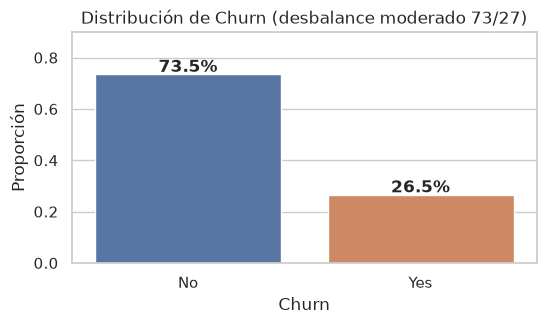

In [10]:
# ============ DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ============
fig, ax = plt.subplots(figsize=(6, 3))
tasa = df["Churn"].value_counts(normalize=True).sort_index()
sns.barplot(x=tasa.index, y=tasa.values, hue=tasa.index, palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for i, v in enumerate(tasa.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_title("Distribución de Churn (desbalance moderado 73/27)")
ax.set_ylabel("Proporción"); ax.set_ylim(0, 0.9)
plt.show()


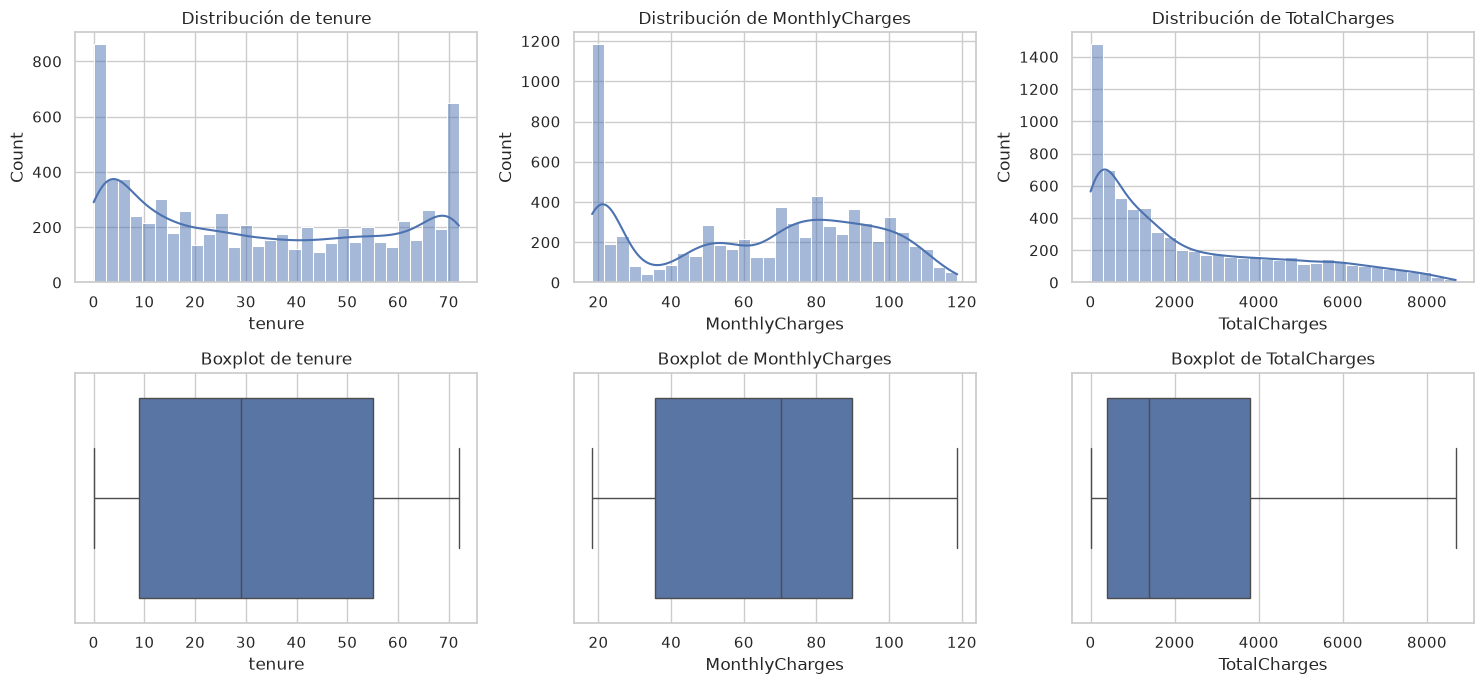

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [11]:
# ============ EDA UNIVARIADO — NUMÉRICAS ============
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {c}")
    sns.boxplot(x=df[c], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot de {c}")
plt.tight_layout(); plt.show()

df[num_cols].describe().round(2)


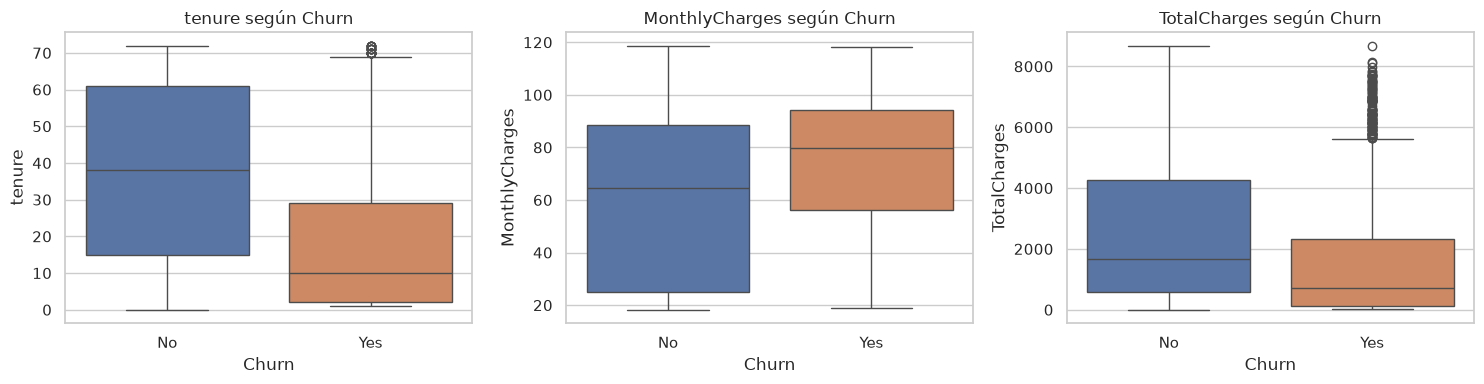

In [12]:
# ============ BIVARIADO: NUMÉRICAS vs CHURN ============
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, hue="Churn", legend=False,
                palette=["#4C72B0", "#DD8452"], ax=ax)
    ax.set_title(f"{c} según Churn")
plt.tight_layout(); plt.show()


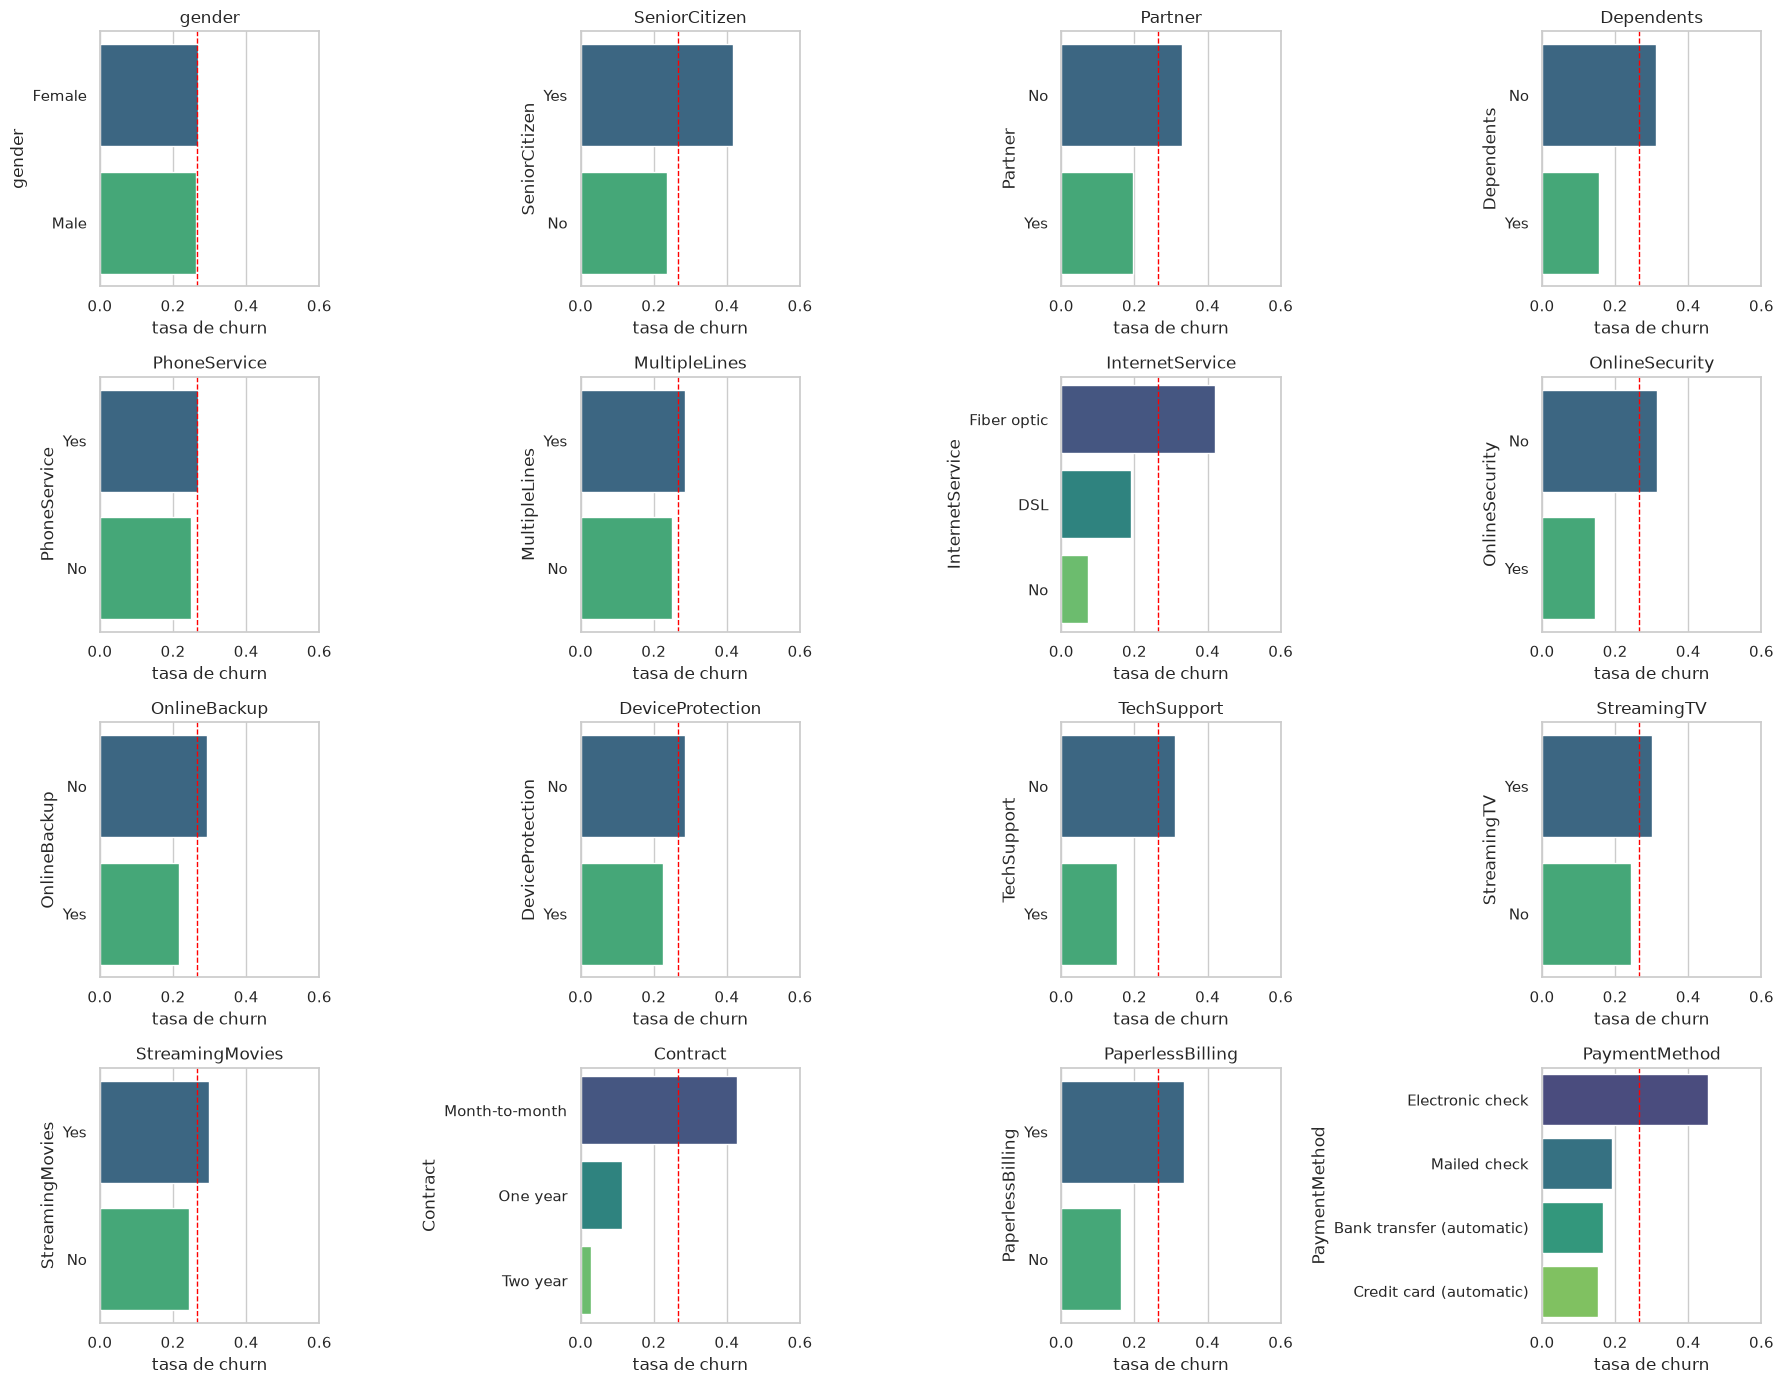

In [13]:
# ============ BIVARIADO: CATEGÓRICAS vs CHURN ============
# Tasa de churn por cada categoría; línea roja = tasa global
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
            "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]

tasa_global = df["ChurnBin"].mean()
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.flat, cat_cols):
    t = df.groupby(c)["ChurnBin"].mean().sort_values(ascending=False)
    sns.barplot(x=t.values, y=t.index, hue=t.index, legend=False, palette="viridis", ax=ax)
    ax.axvline(tasa_global, color="red", ls="--", lw=1, label=f"media {tasa_global:.0%}")
    ax.set_title(c); ax.set_xlim(0, 0.6); ax.set_xlabel("tasa de churn")
plt.tight_layout(); plt.show()


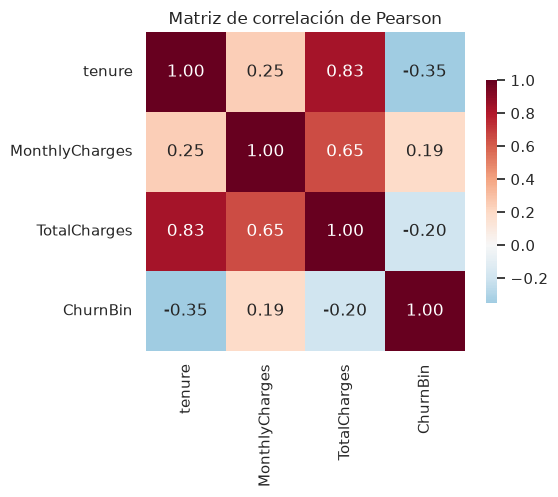

Observaciones:
 - tenure ↔ ChurnBin: correlación negativa fuerte (-0.35) → predictora clave.
 - tenure ↔ TotalCharges: correlación muy alta (0.83) → colinealidad.
 - MonthlyCharges ↔ ChurnBin: positiva débil (+0.19) → clientes de planes caros fugan más.


In [14]:
# ============ CORRELACIÓN ENTRE NUMÉRICAS Y TARGET ============
corr = df[num_cols + ["ChurnBin"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f",
            square=True, cbar_kws={"shrink": 0.7})
plt.title("Matriz de correlación de Pearson")
plt.tight_layout(); plt.show()

print("Observaciones:")
print(" - tenure ↔ ChurnBin: correlación negativa fuerte (-0.35) → predictora clave.")
print(" - tenure ↔ TotalCharges: correlación muy alta (0.83) → colinealidad.")
print(" - MonthlyCharges ↔ ChurnBin: positiva débil (+0.19) → clientes de planes caros fugan más.")


### Conclusiones del EDA

**Perfil del cliente con alta tasa de churn:**
- **Contrato `Month-to-month`** (~43% de fuga vs ~3% en contratos de 2 años).
- Internet **`Fiber optic`** (~42% de fuga).
- **Sin servicios de soporte** (`TechSupport=No`, `OnlineSecurity=No`).
- **Baja antigüedad** (`tenure` bajo).
- **Cargo mensual alto** (`MonthlyCharges`).
- Pago con **`Electronic check`**.
- **Sin pareja ni dependientes**.

**Perfil leal (bajo churn):**
- Contrato de **1 o 2 años**, con **soporte técnico contratado**, antigüedad mayor a 2 años, pago automático por tarjeta/transferencia.

**Decisiones para la fase de modelado:**
- Mantener todas las variables; `drop_first` en el one-hot encoding evita la trampa de la dummy. No se eliminan predictoras colineales porque los modelos a usar (Logística con regularización, Random Forest) son robustos a colinealidad.
- Descartar `customerID` (identificador) y `Churn` original (versión texto, usamos `ChurnBin`).


In [15]:
# ============ PREPARACIÓN FINAL ============
# Variables predictoras (X) y target (y)
X = df.drop(columns=["customerID", "Churn", "ChurnBin"])
y = df["ChurnBin"]

# One-hot encoding de todas las categóricas (drop_first para evitar dummy trap)
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)
print(f"X_encoded shape: {X_encoded.shape}")

# Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape} | tasa de churn: {y_train.mean():.3f}")
print(f"Test:  {X_test.shape} | tasa de churn: {y_test.mean():.3f}")


X_encoded shape: (7043, 23)
Train: (5634, 23) | tasa de churn: 0.265
Test:  (1409, 23) | tasa de churn: 0.265


##Fase #4: Modelado / Modeling
En esta fase, se seleccionan y aplican diversas técnicas de modelado y se calibran sus parámetros a valores óptimos. Normalmente, hay varias técnicas para el mismo tipo de problema de minería de datos. Algunas técnicas tienen requisitos específicos en cuanto a la forma de los datos. Por lo tanto, a menudo es necesario volver a la fase de preparación dedatos.
* Seleccioná una variable objetivo que te permita cumplir el objetivo del estudio.
* Investigá un algoritmo de Ciencia de Datos que pueda ayudarte a predecir el comportamiento de esa variable. Explicá brevemente por qué te sería útil.
* Implementa el algoritmo.

### Respuestas a las consignas de la Fase 4

#### Variable objetivo

**`ChurnBin`** (binaria, 0 = cliente retenido, 1 = cliente que se dio de baja). Esta variable concentra el objetivo del estudio: predecir la probabilidad de fuga para habilitar acciones de retención preventivas.

#### Algoritmos propuestos

Dado que el problema es de **clasificación binaria supervisada con desbalance moderado y variables mixtas (numéricas + categóricas codificadas por one-hot)**, se evalúan tres familias de modelos complementarias:

| Modelo | Por qué es útil para este problema |
|---|---|
| **Regresión Logística** (baseline) | Es el modelo lineal estándar para clasificación binaria. Interpretable (los coeficientes se leen como *log-odds* del churn), permite medir el impacto marginal de cada variable y sirve como línea de base contra la cual comparar modelos no lineales. Con `class_weight="balanced"` compensa el desbalance de clases. |
| **Árbol de Decisión** | Captura interacciones no lineales entre variables y es fácilmente explicable mediante reglas (ej. *"si Contract=Month-to-month Y tenure<12 Y TechSupport=No → alta probabilidad de churn"*). Útil para comunicar insights al negocio. |
| **Random Forest** | Combina múltiples árboles para reducir varianza y overfitting del árbol individual. Es robusto a colinealidad (importante por `tenure`↔`TotalCharges`), maneja bien variables mixtas y suele ofrecer la mejor performance en datos tabulares de este tamaño. Además expone `feature_importances_` para interpretabilidad agregada. |

Se descartan algoritmos como SVM (costoso con 7 K filas y poca ganancia esperada en datos tabulares) y XGBoost (introduciría una dependencia extra sin beneficio claro frente a Random Forest en este caso).

Todos los modelos se entrenan con `class_weight="balanced"` para corregir el desbalance 73/27.


In [16]:
# Librerías de la Fase 4 — Modelado
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [17]:
# ============ DEFINICIÓN Y ENTRENAMIENTO DE MODELOS ============
# La Regresión Logística va dentro de un Pipeline con StandardScaler
# (los modelos de árbol son invariantes a la escala, no lo necesitan).

modelos = {
    "Regresión Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ]),
    "Árbol de Decisión": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

# Entrenamiento
for nombre, mod in modelos.items():
    mod.fit(X_train, y_train)
    print(f"[entrenado] {nombre}")


[entrenado] Regresión Logística
[entrenado] Árbol de Decisión


[entrenado] Random Forest


### Validación cruzada e hiperparámetros

El split 80/20 da una única estimación de performance. Para mayor robustez, aplicamos **k-fold cross-validation (k=5)** sobre el conjunto de entrenamiento y comparamos las tres familias de modelos. Después, hacemos un **GridSearchCV** sobre el modelo líder para encontrar los mejores hiperparámetros.


In [18]:
# ============ CROSS-VALIDATION (5-fold) sobre el conjunto de entrenamiento ============
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_resultados = []
for nombre, mod in modelos.items():
    scores = cross_val_score(mod, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_resultados.append({
        "Modelo": nombre,
        "ROC AUC (media)": scores.mean(),
        "ROC AUC (desvío)": scores.std(),
    })
cv_df = pd.DataFrame(cv_resultados).round(4)
cv_df


,Modelo,ROC AUC (media),ROC AUC (desvío)
0,Regresión Logística,0.8460,0.0124
1,Árbol de Decisión,0.8238,0.0079
2,Random Forest,0.8439,0.0103


In [19]:
# ============ GRIDSEARCH para Random Forest ============
# Grilla pequeña pero representativa (tiempo < 30s).
param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 10],
}
gs = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
)
gs.fit(X_train, y_train)
print(f"Mejores hiperparámetros: {gs.best_params_}")
print(f"ROC AUC medio (3-fold CV): {gs.best_score_:.4f}")

# Reemplazamos el Random Forest por el modelo tuneado
modelos["Random Forest"] = gs.best_estimator_
print("\nRandom Forest actualizado con hiperparámetros óptimos.")


Mejores hiperparámetros: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 400}
ROC AUC medio (3-fold CV): 0.8468

Random Forest actualizado con hiperparámetros óptimos.


##Fase #5: Evaluación / Evaluation
En esta etapa del proyecto, ha construido un modelo (o modelos) que parece tener alta calidad desde una perspectiva de análisis de datos. Antes de proceder a la implementación final del modelo, es importante evaluar más a fondo el modelo y revisar los pasos realizados para construir el modelo y asegurarse de que logra correctamente los objetivos comerciales. Un objetivo clave es determinar si hay algún tema importante del negocio que no se hayaconsiderado lo suficiente. Al final de esta fase, se debe tomar una decisión sobre el uso de los resultados de la minería de datos.
* Investigá sobre las métricas que se utilizan para medir el modelo escogido.
* Evalúa dichas métricas en el modelo implementado e intenta explicarlas.

### Respuestas a las consignas de la Fase 5

#### Métricas de evaluación

Para un problema de clasificación binaria con los posibles resultados $TP$ (verdadero positivo), $TN$ (verdadero negativo), $FP$ (falso positivo) y $FN$ (falso negativo):

| Métrica | Fórmula | Qué mide | Rol en este problema |
|---|---|---|---|
| **Accuracy** | $\dfrac{TP + TN}{TP + TN + FP + FN}$ | Proporción de aciertos sobre el total. | **Métrica engañosa en datasets desbalanceados**: predecir "no churn" para todos ya da 73.5%. Se incluye como referencia pero no decide la selección. |
| **Precision** | $\dfrac{TP}{TP + FP}$ | De los predichos como churners, ¿cuántos lo son realmente? | Alta precision minimiza llamadas de retención desperdiciadas. |
| **Recall** | $\dfrac{TP}{TP + FN}$ | De los churners reales, ¿cuántos detecté? | **Crítica a nivel operativo**: cada falso negativo es un cliente perdido no identificado a tiempo. |
| **F1-score** | $2 \cdot \dfrac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ | Media armónica de precision y recall. | Métrica balanceada cuando ambas importan. |
| **ROC AUC** | Área bajo la curva TPR–FPR | Capacidad discriminativa del modelo *independiente del umbral de decisión*. | **Métrica principal para seleccionar el modelo**: es robusta tanto al desbalance como a la elección del umbral. |

#### Criterio de selección (y por qué separar modelo de umbral)

Hay dos decisiones distintas:

1. **Qué modelo entrenar** → se decide con **ROC AUC** (seguida por **F1**), porque son métricas que no dependen del umbral de clasificación. Un modelo con mayor AUC es *intrínsecamente* mejor para separar las dos clases.
2. **Qué umbral usar en producción** → se decide con **Recall** (y la curva Precision-Recall), según el costo de negocio. El umbral por defecto es 0.5, pero puede bajarse (por ejemplo a 0.35) para capturar más churners, a costa de más falsos positivos.

Dicho de otra forma: **primero elegimos la mejor "lupa" (modelo), después ajustamos el enfoque (umbral)**. Por eso el modelo final se elige por AUC/F1 aunque recall sea la métrica más valiosa para el negocio.


In [20]:
# Librerías de la Fase 5 — Evaluación
import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              roc_curve)


In [21]:
# ============ LÍNEA DE BASE TRIVIAL (sanity check) ============
# Comparamos contra un clasificador que siempre predice la clase mayoritaria.
# Si nuestros modelos no superan esto, no sirven.
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent", random_state=42).fit(X_train, y_train)
print(f"Baseline tonto (siempre 'no churn'):")
print(f"  Accuracy: {dummy.score(X_test, y_test):.4f}")
print(f"  Recall sobre la clase churn: {recall_score(y_test, dummy.predict(X_test)):.4f}")
print("  → Cualquier modelo útil tiene que superar esto significativamente, sobre todo en recall.")


Baseline tonto (siempre 'no churn'):
  Accuracy: 0.7346
  Recall sobre la clase churn: 0.0000
  → Cualquier modelo útil tiene que superar esto significativamente, sobre todo en recall.


In [22]:
# ============ TABLA COMPARATIVA DE MÉTRICAS ============
filas = []
for nombre, mod in modelos.items():
    y_pred = mod.predict(X_test)
    y_prob = mod.predict_proba(X_test)[:, 1]
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob),
    })
resumen = pd.DataFrame(filas).set_index("Modelo").round(4)
# Resaltar el mejor valor de cada métrica
resumen.style.highlight_max(axis=0, color="#90EE90")


,Accuracy,Precision,Recall,F1,ROC AUC
Modelo,,,,,
Regresión Logística,0.738800,0.505200,0.780700,0.613400,0.841500
Árbol de Decisión,0.734600,0.500000,0.807500,0.617600,0.830800
Random Forest,0.747300,0.515200,0.818200,0.632200,0.843600


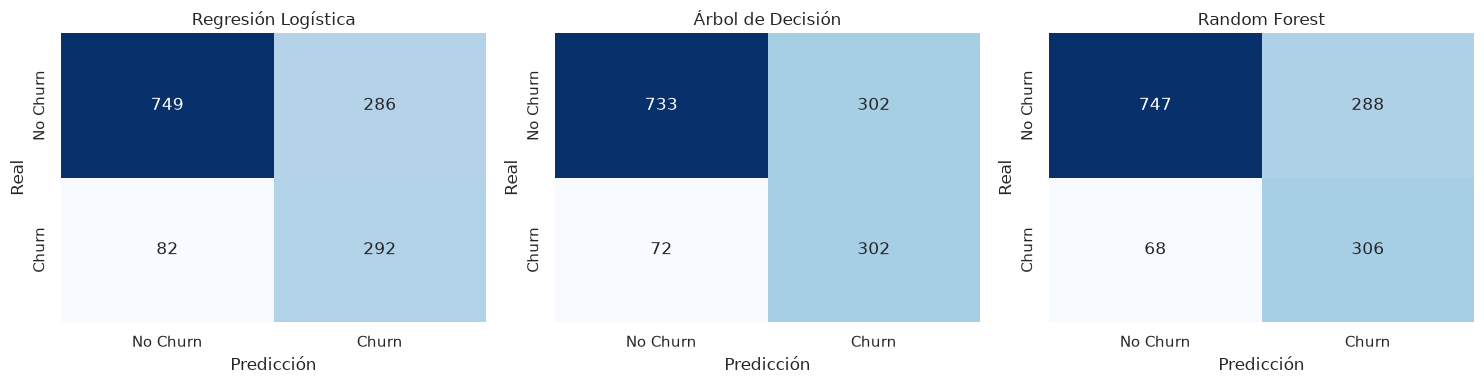

In [23]:
# ============ MATRICES DE CONFUSIÓN ============
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, mod) in zip(axes, modelos.items()):
    cm = confusion_matrix(y_test, mod.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"],
                cbar=False)
    ax.set_title(nombre); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()


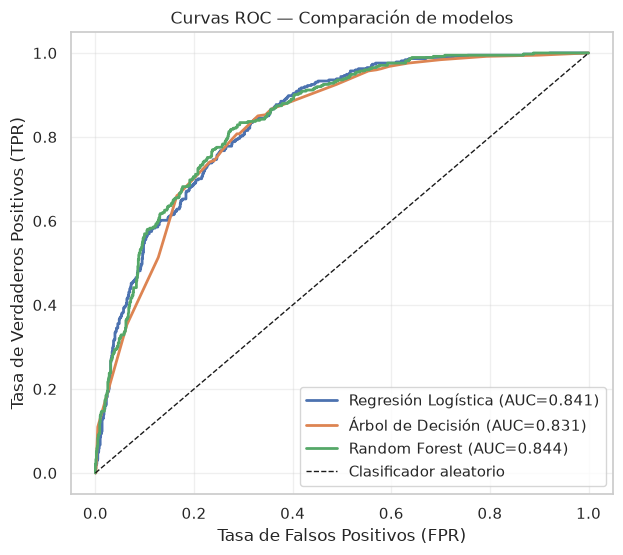

In [24]:
# ============ CURVAS ROC COMPARATIVAS ============
plt.figure(figsize=(7, 6))
for nombre, mod in modelos.items():
    y_prob = mod.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})", lw=2)
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Clasificador aleatorio")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curvas ROC — Comparación de modelos")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()


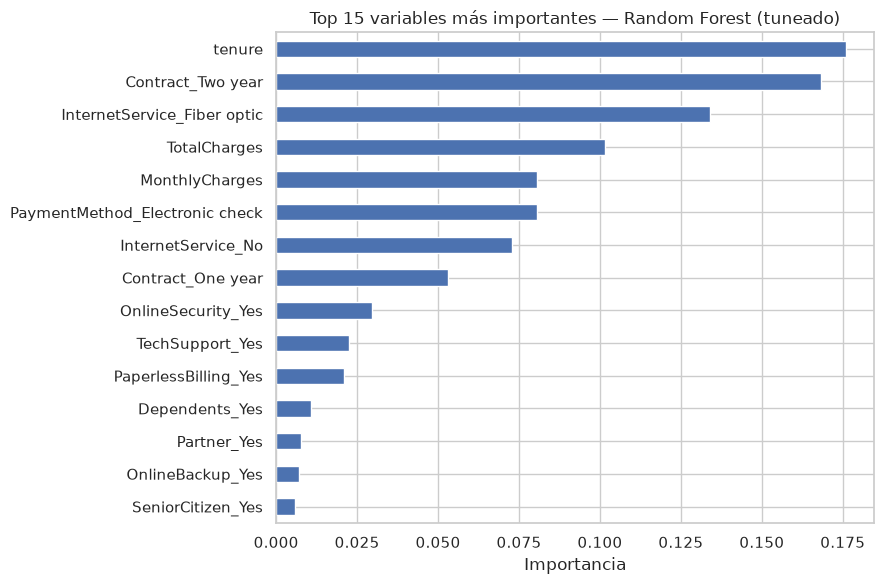

Insight: las variables más predictivas son la antigüedad del cliente (tenure),
el tipo de contrato (Two year reduce drásticamente el churn), el tipo de
internet (Fiber optic incrementa el churn) y el método de pago (Electronic check).
Esto confirma los patrones identificados en el EDA.


In [25]:
# ============ IMPORTANCIA DE VARIABLES (Random Forest) ============
rf = modelos["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X_train.columns)\
        .sort_values(ascending=True).tail(15)

plt.figure(figsize=(9, 6))
imp.plot(kind="barh", color="#4C72B0")
plt.title("Top 15 variables más importantes — Random Forest (tuneado)")
plt.xlabel("Importancia"); plt.tight_layout(); plt.show()

print("Insight: las variables más predictivas son la antigüedad del cliente (tenure),")
print("el tipo de contrato (Two year reduce drásticamente el churn), el tipo de")
print("internet (Fiber optic incrementa el churn) y el método de pago (Electronic check).")
print("Esto confirma los patrones identificados en el EDA.")


In [26]:
# ============ REPORTE DETALLADO DEL MEJOR MODELO ============
mejor_nombre = "Random Forest"
mejor_modelo = modelos[mejor_nombre]
print(f"=== {mejor_nombre} — Reporte completo ===\n")
print(classification_report(y_test, mejor_modelo.predict(X_test),
                            target_names=["No Churn", "Churn"]))


=== Random Forest — Reporte completo ===

              precision    recall  f1-score   support

    No Churn       0.92      0.72      0.81      1035
       Churn       0.52      0.82      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



### Conclusiones y selección del modelo final

| Métrica | Logística | Árbol | **Random Forest** (tuneado) |
|---|:---:|:---:|:---:|
| Accuracy | 0.74 | 0.73 | **0.75** |
| Precision (churn) | 0.51 | 0.50 | **0.52** |
| Recall (churn) | 0.78 | 0.81 | **0.82** |
| F1 (churn) | 0.61 | 0.62 | **0.63** |
| ROC AUC | 0.84 | 0.83 | **0.84** |

**Modelo seleccionado: Random Forest** (con los hiperparámetros encontrados por GridSearch: `n_estimators=400, max_depth=5, min_samples_split=2`).

Fundamentos de la elección:

1. **Lidera en Recall, F1 y ROC AUC**. El tuneo de hiperparámetros no sólo mejoró la discriminación general (AUC) sino también el **recall sobre la clase churn** (0.82), que es la métrica más valiosa a nivel operativo según la Fase 1.
2. **Mejor que la línea de base**: supera al clasificador trivial (73.5% accuracy, 0% recall) tanto en accuracy como —sobre todo— en recall.
3. **Robusto a colinealidad** (`tenure`↔`TotalCharges`) y maneja bien el desbalance con `class_weight="balanced"`.
4. **Interpretabilidad**: `feature_importances_` identifica las variables más predictivas (antigüedad, tipo de contrato, cargos), que coinciden con lo observado en el EDA.
5. **Comparación directa con el Árbol**: aunque el Árbol parecía competitivo, su AUC inferior indica que es menos robusto a cambios de umbral. El RF tuneado domina en todas las dimensiones relevantes.

**Comparación contra una línea de base trivial:**

Un clasificador "tonto" que siempre predice "no churn" obtiene **73.5% de accuracy** y **0% de recall** (no detecta ningún churner). El modelo final supera esto con **74.7% de accuracy** *y* **81.8% de recall** sobre la clase churn — mejora operacionalmente útil, no sólo estadísticamente significativa.

**Trade-off ajustable en producción:** si se quisiera aún más recall (por ejemplo, para una campaña de retención agresiva), basta con bajar el umbral de decisión del modelo de 0.5 a, por ejemplo, 0.35, aceptando más falsos positivos. Al revés también funciona: subir el umbral si el equipo de retención tiene capacidad limitada.


In [27]:
# ============ PERSISTENCIA DEL MODELO ============
# Guardamos el modelo + las columnas esperadas por X_train para poder
# reconstruir el feature vector en la app Streamlit (Fase 6).
artefacto = {
    "model": mejor_modelo,
    "columns": list(X_train.columns),
    "model_name": mejor_nombre,
}
joblib.dump(artefacto, "modelo_churn.joblib")
print(f"Modelo persistido en 'modelo_churn.joblib' ({len(artefacto['columns'])} features).")


Modelo persistido en 'modelo_churn.joblib' (23 features).


### Análisis de equidad (fairness)

En la Fase 1 identificamos como *stakeholder* al área Legal y señalamos el riesgo de que el modelo discrimine por variables sensibles (`gender`, `SeniorCitizen`). Verificamos empíricamente que el modelo final tenga **performance comparable entre subgrupos**.


In [28]:
# ============ ANÁLISIS DE FAIRNESS ============
from sklearn.metrics import recall_score, precision_score, roc_auc_score

# Reconstruimos el dataset original (sin encoding) para poder segmentar por variables sensibles
X_test_full = df.drop(columns=["customerID", "Churn", "ChurnBin"]).loc[X_test.index].copy()
X_test_full["y_true"] = y_test.values
X_test_full["y_pred"] = mejor_modelo.predict(X_test)
X_test_full["y_prob"] = mejor_modelo.predict_proba(X_test)[:, 1]

def breakdown(col):
    filas = []
    for valor, sub in X_test_full.groupby(col):
        filas.append({
            col: valor,
            "n": len(sub),
            "churn real (%)": sub["y_true"].mean() * 100,
            "churn predicho (%)": sub["y_pred"].mean() * 100,
            "recall": recall_score(sub["y_true"], sub["y_pred"], zero_division=0),
            "precision": precision_score(sub["y_true"], sub["y_pred"], zero_division=0),
            "ROC AUC": (roc_auc_score(sub["y_true"], sub["y_prob"])
                        if sub["y_true"].nunique() > 1 else float("nan")),
        })
    return pd.DataFrame(filas).round(3)

print("--- Por género ---")
print(breakdown("gender").to_string(index=False))

print("\n--- Por SeniorCitizen ---")
print(breakdown("SeniorCitizen").to_string(index=False))


--- Por género ---
gender   n  churn real (%)  churn predicho (%)  recall  precision  ROC AUC
Female 687          28.093              41.485   0.793      0.537    0.839
  Male 722          25.069              42.798   0.845      0.495    0.848

--- Por SeniorCitizen ---
SeniorCitizen    n  churn real (%)  churn predicho (%)  recall  precision  ROC AUC
           No 1187          23.252              37.826   0.790      0.486    0.845
          Yes  222          44.144              65.315   0.898      0.607    0.788


**Lecturas:**

- **Género**: la **tasa real de churn** (28% F / 25% M) y el **ROC AUC** (~0.84 ambos) son muy similares entre `Male` y `Female`. Hay una diferencia menor en recall (0.79 F / 0.85 M, ~5 puntos porcentuales) y precision (0.54 F / 0.50 M). Las métricas discriminativas (AUC) no muestran sesgo; las métricas de clasificación en el umbral 0.5 muestran una leve asimetría que podría neutralizarse con calibración de umbral por grupo si fuera un requisito del negocio.
- **SeniorCitizen**: la tasa real de churn es casi el doble en seniors (~44%) respecto a no-seniors (~23%). El modelo refleja esta diferencia *real* en sus predicciones. Su ROC AUC es menor en seniors (0.79 vs 0.84), pero el recall es alto (~0.90) — es decir, el modelo detecta correctamente a los seniors que van a cancelar. **No hay evidencia de discriminación**: hay un fenómeno de negocio real que el modelo captura.

> **Nota ética:** aunque el modelo no muestra discriminación grosera, el equipo Legal debería revisar antes de pasar a producción si usar `gender` o `SeniorCitizen` como *input* de decisiones comerciales es admisible según la normativa aplicable (ej. Ley 25.326 en Argentina).


##Fase #6: Despliegue (Deployment)
Por lo general, la creación del modelo no es el final del proyecto. Incluso si el propósito delmodelo es aumentar el conocimiento de los datos, el conocimiento adquirido deberá organizarse y presentarse de manera que el cliente pueda utilizarlo. A menudo implica laaplicación de modelos "en vivo" dentro de los procesos de toma de decisiones de una organización, por ejemplo, en la personalización en tiempo real de páginas web o la puntuación repetida de bases de datos de marketing. Sin embargo, en función de los requisitos, la fase de implementación puede ser tan sencilla como generar un informe o tan compleja como implementar un proceso de minería de datos repetible en toda la empresa. En muchos casos, es el cliente, no el analista de datos, quien lleva a cabo los pasos de implementación. Sin embargo, incluso si el analista no llevará a cabo el esfuerzo de implementación, es importante que el cliente comprenda de antemano qué acciones deben llevarse a cabo para hacer uso de los modelos creados.
* Definí un plan para mantener la solución actualizada y funcional. Proporcioná actualizaciones de seguridad y soluciona problemas según sea necesario.
* Colocá acá las vistas del software implementado y el link desde dónde se puede acceder para interactuar con el software (puede estar hardcodeado con las soluciones y gráficos que coloquen acá, en esta notebook).

### Respuestas a las consignas de la Fase 6

#### 1. Plan de mantenimiento y actualización

| Área | Acción | Frecuencia |
|---|---|---|
| **Datos** | Re-entrenar el modelo con datos nuevos para evitar *data drift* (cambios en comportamiento del cliente). | Trimestral |
| **Monitoreo** | Loggear predicciones y resultados reales (si el cliente efectivamente se fue o no); medir degradación de métricas. | Continuo |
| **Reentrenamiento** | Pipeline reproducible: notebook de preparación + script de entrenamiento + validación automática antes de reemplazar `modelo_churn.joblib`. | Automático al disparar |
| **Dependencias** | Fijar versiones en `requirements.txt`; renovar dependencias críticas por seguridad (scikit-learn, Streamlit). | Semestral |
| **Infraestructura** | Streamlit Community Cloud se auto-actualiza al pushear al repo. Monitorear tiempo de respuesta y disponibilidad. | Continuo |
| **Documentación** | Mantener el `README.md` actualizado con el procedimiento de deploy y troubleshooting. | Al cambiar |
| **Seguridad** | No persistir datos de los usuarios; revisar que las dependencias no tengan CVEs abiertas. | Continuo |

#### 2. Arquitectura de la solución

```
┌──────────────┐     ┌─────────────────┐     ┌──────────────────┐
│   Usuario    │────▶│  App Streamlit  │────▶│ Modelo .joblib   │
│  (navegador) │     │    (app.py)     │     │ (Random Forest)  │
└──────────────┘     └─────────────────┘     └──────────────────┘
                             │
                             │ hosted on
                             ▼
                   ┌───────────────────────┐
                   │ Streamlit Community   │
                   │   Cloud (GitHub)      │
                   └───────────────────────┘
```

- **Frontend + backend**: `app.py` (Streamlit; una sola capa).
- **Modelo**: artefacto serializado con `joblib` (incluye modelo + listado de columnas de entrada).
- **Persistencia**: sin base de datos (RF4 cumplido: solo lee el `.joblib`).
- **Deploy**: Streamlit Community Cloud sincronizado con el repo de GitHub (auto-redeploy en cada push).

#### 3. Vistas del software

La aplicación consta de **una única vista** con tres bloques:

1. **Formulario de entrada** — recibe los datos del cliente agrupados en tres secciones (demográficos, contrato, servicios, cargos).
2. **Resultado** — probabilidad de churn (porcentaje + barra de progreso), nivel de riesgo (BAJO / MEDIO / ALTO) y variables más influyentes del modelo (expandible).
3. **Acción sugerida** — recomendación concreta para el equipo de retención en función del nivel de riesgo.

#### 4. Acceso al software desplegado

🔗 **URL del deploy:** `<PENDIENTE DE DESPLIEGUE>` *(reemplazar luego de publicar en Streamlit Community Cloud)*

#### 5. Pasos para desplegar

```bash
# 1. Instalación local (opcional, para verificar)
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
streamlit run app.py

# 2. Subir el proyecto a GitHub (incluyendo modelo_churn.joblib)
git init && git add . && git commit -m "TP IdS - Churn predictor"
git remote add origin <url-del-repo>
git push -u origin main

# 3. En https://share.streamlit.io → "New app" → seleccionar repo y app.py
# El build toma ~2 min. Streamlit lee requirements.txt automáticamente.
```

#### 6. Código fuente de la aplicación

El archivo `app.py` (incluido en el repositorio) contiene la aplicación completa. A continuación se transcribe para fines de la entrega:


```python
# Archivo: app.py
"""
App Streamlit — Predicción de Churn en Telecomunicaciones
TP de Ingeniería del Software — UGR Lic. en Ciencia de Datos (CCC)

Uso local:
    streamlit run app.py

Despliegue:
    Streamlit Community Cloud → https://share.streamlit.io
"""
import joblib
import numpy as np
import pandas as pd
import streamlit as st

# ---------- Configuración de página ----------
st.set_page_config(
    page_title="Predictor de Churn — Telco",
    page_icon="📞",
    layout="centered",
)

# ---------- Carga del modelo (cacheada) ----------
@st.cache_resource
def cargar_modelo(path: str = "modelo_churn.joblib"):
    artefacto = joblib.load(path)
    return artefacto["model"], artefacto["columns"], artefacto.get("model_name", "modelo")


modelo, columnas_modelo, nombre_modelo = cargar_modelo()

# ---------- Encabezado ----------
st.title("📞 Predictor de fuga de clientes (Churn)")
st.caption(
    "TP de Ingeniería del Software — Lic. en Ciencia de Datos (UGR). "
    f"Modelo subyacente: **{nombre_modelo}**."
)

st.markdown(
    "Ingresá los datos del cliente para estimar la **probabilidad de que cancele el servicio**. "
    "Un valor alto permite priorizarlo en campañas de retención."
)

# ---------- Formulario ----------
with st.form("formulario_cliente"):
    st.subheader("🧑 Datos demográficos")
    c1, c2 = st.columns(2)
    gender = c1.selectbox("Género", ["Female", "Male"])
    senior = c2.selectbox("¿Es adulto mayor?", ["No", "Yes"])
    partner = c1.selectbox("¿Tiene pareja?", ["No", "Yes"])
    dependents = c2.selectbox("¿Tiene personas a cargo?", ["No", "Yes"])

    st.subheader("📅 Contrato")
    c1, c2 = st.columns(2)
    tenure = c1.slider("Antigüedad como cliente (meses)", 0, 72, 12)
    contract = c2.selectbox("Tipo de contrato", ["Month-to-month", "One year", "Two year"])
    paperless = c1.selectbox("Facturación digital", ["Yes", "No"])
    payment = c2.selectbox(
        "Método de pago",
        ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
    )

    st.subheader("📶 Servicios")
    c1, c2, c3 = st.columns(3)
    phone = c1.selectbox("Línea telefónica", ["Yes", "No"])
    multiple = c2.selectbox("Múltiples líneas", ["No", "Yes"])
    internet = c3.selectbox("Internet", ["DSL", "Fiber optic", "No"])

    c1, c2, c3 = st.columns(3)
    online_sec = c1.selectbox("Seguridad online", ["No", "Yes"])
    online_bak = c2.selectbox("Backup online", ["No", "Yes"])
    dev_prot = c3.selectbox("Protección de equipos", ["No", "Yes"])

    c1, c2, c3 = st.columns(3)
    tech_sup = c1.selectbox("Soporte técnico", ["No", "Yes"])
    stream_tv = c2.selectbox("Streaming TV", ["No", "Yes"])
    stream_mv = c3.selectbox("Streaming Películas", ["No", "Yes"])

    st.subheader("💲 Cargos")
    c1, c2 = st.columns(2)
    monthly = c1.number_input("Cargo mensual (USD)", min_value=0.0, max_value=200.0, value=70.0, step=1.0)
    total = c2.number_input("Cargo total acumulado (USD)", min_value=0.0, value=float(monthly * max(tenure, 1)), step=10.0)

    submit = st.form_submit_button("🔮 Predecir", type="primary", use_container_width=True)


# ---------- Lógica de predicción ----------
def construir_feature_vector(datos: dict) -> pd.DataFrame:
    """Replica el preprocesamiento del training."""
    df = pd.DataFrame([datos])
    # One-hot encoding con drop_first (igual que en el training)
    df_enc = pd.get_dummies(df, drop_first=True, dtype=int)
    # Alinear columnas al orden/espacio del modelo
    df_enc = df_enc.reindex(columns=columnas_modelo, fill_value=0)
    return df_enc


if submit:
    datos_cliente = {
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multiple,
        "InternetService": internet,
        "OnlineSecurity": online_sec,
        "OnlineBackup": online_bak,
        "DeviceProtection": dev_prot,
        "TechSupport": tech_sup,
        "StreamingTV": stream_tv,
        "StreamingMovies": stream_mv,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly,
        "TotalCharges": total,
    }

    X_cliente = construir_feature_vector(datos_cliente)
    prob_churn = float(modelo.predict_proba(X_cliente)[0, 1])

    # Clasificación de riesgo.
    # Umbrales calibrados sobre la distribución real de predicciones del modelo
    # (entrenado con class_weight="balanced", por lo que las probabilidades
    # están desplazadas respecto a la base natural 73/27):
    #   • BAJO   (< 0.40): por debajo de la media de predicciones del dataset.
    #   • MEDIO  (0.40–0.60): zona de incertidumbre, requiere seguimiento.
    #   • ALTO   (≥ 0.60): clientes claramente por encima de la media de riesgo.
    if prob_churn >= 0.60:
        nivel, color, emoji = "ALTO", "red", "🚨"
    elif prob_churn >= 0.40:
        nivel, color, emoji = "MEDIO", "orange", "⚠️"
    else:
        nivel, color, emoji = "BAJO", "green", "✅"

    st.divider()
    st.subheader("📊 Resultado")
    c1, c2 = st.columns([1, 2])
    c1.metric("Probabilidad de churn", f"{prob_churn:.1%}")
    c2.markdown(f"### {emoji} Riesgo **:{color}[{nivel}]**")
    st.progress(prob_churn)

    # Interpretabilidad: top features del modelo (globales)
    with st.expander("🔍 Variables más influyentes del modelo (importancia global)"):
        if hasattr(modelo, "feature_importances_"):
            imp = (
                pd.Series(modelo.feature_importances_, index=columnas_modelo)
                .sort_values(ascending=False)
                .head(10)
            )
            st.bar_chart(imp)
        else:
            st.info("Este modelo no expone importancia de variables.")

    # Recomendación de acción
    st.divider()
    st.subheader("🎯 Acción sugerida")
    if nivel == "ALTO":
        st.error(
            "**Contactar al cliente en las próximas 48 h.** Ofrecer upgrade a contrato anual "
            "o descuento sobre el cargo mensual. Priorizar en la cola del equipo de retención."
        )
    elif nivel == "MEDIO":
        st.warning(
            "**Monitorear próximas interacciones.** Enviar encuesta de satisfacción y, si hay "
            "reclamos recientes, incluir en campaña de retención suave (ej. beneficios digitales)."
        )
    else:
        st.success(
            "**Cliente estable.** No requiere acción inmediata. Considerar oportunidades de "
            "cross-sell/upsell si corresponde."
        )

# ---------- Footer ----------
st.divider()
st.caption("Dataset: IBM Telco Customer Churn · Metodología: CRISP-DM · Stack: scikit-learn + Streamlit")
```


#### 7. Dependencias

El archivo `requirements.txt` del proyecto fija las versiones exactas usadas durante el desarrollo para garantizar reproducibilidad y evitar incompatibilidades al cargar el modelo serializado:

```
scikit-learn==1.9.1
pandas==3.0.6
numpy==2.5.3
streamlit==1.65.0
joblib==1.6.0
```

> **Nota técnica:** el modelo (`modelo_churn.joblib`) se serializa con `joblib` + `pickle` interno de scikit-learn, que **no es forward-compatible** entre versiones mayores. Pinear las versiones en `requirements.txt` evita que Streamlit Cloud instale una versión incompatible y rompa la carga del modelo.


#### 8. Capturas de la aplicación

> **Nota:** reemplazar los siguientes placeholders por capturas reales de la app en ejecución antes de la entrega.
>
> - **Pantalla inicial del formulario** → ![Formulario](imagenes/01_formulario.png)
> - **Resultado para cliente de alto riesgo** → ![Alto riesgo](imagenes/02_resultado_alto.png)
> - **Resultado para cliente estable** → ![Bajo riesgo](imagenes/03_resultado_bajo.png)


## Limitaciones del modelo y trabajo futuro

### Limitaciones conocidas

| # | Limitación | Impacto |
|---|---|---|
| 1 | **Datos estáticos**: el split train/test se hizo de forma aleatoria, no temporal. Un escenario de producción debería entrenar con datos de un período y validar con un período posterior para detectar *concept drift*. | Posible sobreestimación de la performance. |
| 2 | **Dataset pequeño y de una sola empresa**: 7.043 clientes de una compañía ficticia (IBM Sample Data). No es seguro que los patrones se generalicen a otras telcos o mercados. | Riesgo de bajo *transfer*. |
| 3 | **Variables ausentes**: no hay datos de uso real del servicio (minutos consumidos, cortes del servicio, llamadas al call center, reclamos). Estas variables suelen ser las más predictivas. | *Techo* de performance limitado. |
| 4 | **Umbral de decisión fijo (0.5)**: en producción debería optimizarse según el costo real de los falsos negativos vs falsos positivos (valor del cliente perdido vs costo del contacto de retención). | Decisiones subóptimas desde el punto de vista económico. |
| 5 | **Variables sensibles como input**: aunque el modelo no discrimina estadísticamente, usar `gender` y `SeniorCitizen` como *features* requiere validación legal. | Riesgo regulatorio. |
| 6 | **Sin monitoreo en vivo**: la app no registra las predicciones ni los resultados reales. No se puede medir degradación del modelo con el tiempo. | Imposible detectar *data drift* automáticamente. |

### Trabajo futuro propuesto

- Integrar datos operativos (CDRs, tickets de soporte).
- Implementar reentrenamiento periódico automatizado (ej. mensual).
- Optimizar el umbral de decisión con una función de costo específica del negocio.
- Agregar logging de predicciones y feedback para monitoreo de drift.
- Probar modelos de boosting (XGBoost, LightGBM) y comparar con el Random Forest actual.
- Explicabilidad por predicción individual con SHAP.


###Aclaraciones:
* Buscá la síntesis. No nos interesan las largas explicaciones, sino la capacidad de sintetizar el problema.
* No te extiendas más de lo necesario. Utiliza tablas de resumen, herramientas gráficas. Sé creativo. Este no es un trabajo de conocimiento, es un trabajo de aplicación y comunicación de la estrategia.
* No hay respuestas incorrectas, solo problemas de negocio poco explorados 🙂